## 1. Introduction

This notebook focuses on visualizing the Student Performance dataset
to identify patterns, distributions, and relationships between
student characteristics and academic performance.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


Load the dataset

In [4]:
df = pd.read_csv("../data/processed/student_performance_cleaned.csv")

Check the dataset 

In [5]:
print("Dataset shape:", df.shape)
print("Number of columns:", len(df.columns))

Dataset shape: (401, 46)
Number of columns: 46


Define variable groups

In [6]:
numerical_cols = [
    "age", "Medu", "Fedu", "traveltime", "studytime",
    "failures", "famrel", "freetime", "goout",
    "Dalc", "Walc", "health", "absences",
    "G1", "G2", "G3"
]

binary_cols = [
    "school", "sex", "address", "famsize", "Pstatus",
    "schoolsup", "famsup", "paid", "activities",
    "nursery", "higher", "internet", "romantic"
]

encoded_cols = [
    "Mjob_at_home", "Mjob_health", "Mjob_other",
    "Mjob_services", "Mjob_teacher",
    "Fjob_at_home", "Fjob_health", "Fjob_other",
    "Fjob_services", "Fjob_teacher",
    "reason_course", "reason_home", "reason_other",
    "reason_reputation",
    "guardian_father", "guardian_mother", "guardian_other"
]

target = "G3"

Check that all columns exist

In [7]:
for group_name, columns in {
    "Numerical": numerical_cols,
    "Binary": binary_cols,
    "Encoded": encoded_cols
}.items():

    missing = set(columns) - set(df.columns)

    print(f"{group_name} missing columns:", missing)

Numerical missing columns: set()
Binary missing columns: set()
Encoded missing columns: set()


# 2. Univariate analysis – Numerical variables 

## 2.1 Statistical summary

In [8]:
df[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,401.0,1.134033e-15,1.001249,-1.331074,-0.537968,0.255139,1.048246,4.220673
Medu,401.0,8.859635e-18,1.001249,-2.588147,-0.721516,0.211800,1.145115,1.145115
Fedu,401.0,1.594734e-16,1.001249,-2.319083,-0.472107,-0.472107,0.451381,1.374868
traveltime,401.0,-1.683331e-16,1.001249,-0.626994,-0.626994,-0.626994,0.785503,3.610498
studytime,401.0,2.657891e-17,1.001249,-1.241358,-1.241358,-0.033143,-0.033143,2.383287
failures,401.0,-3.100872e-17,1.001249,-0.435853,-0.435853,-0.435853,-0.435853,3.725506
famrel,401.0,1.351094e-16,1.001249,-3.322653,0.050471,0.050471,1.174845,1.174845
freetime,401.0,-1.284647e-16,1.001249,-2.302210,-0.227634,-0.227634,0.809654,1.846942
goout,401.0,1.151753e-16,1.001249,-1.901649,-0.999210,-0.096770,0.805669,1.708108
Dalc,401.0,-8.859635e-17,1.001249,-0.537112,-0.537112,-0.537112,0.639838,4.170690


## 2.2 Histograms – Distribution of numerical variables

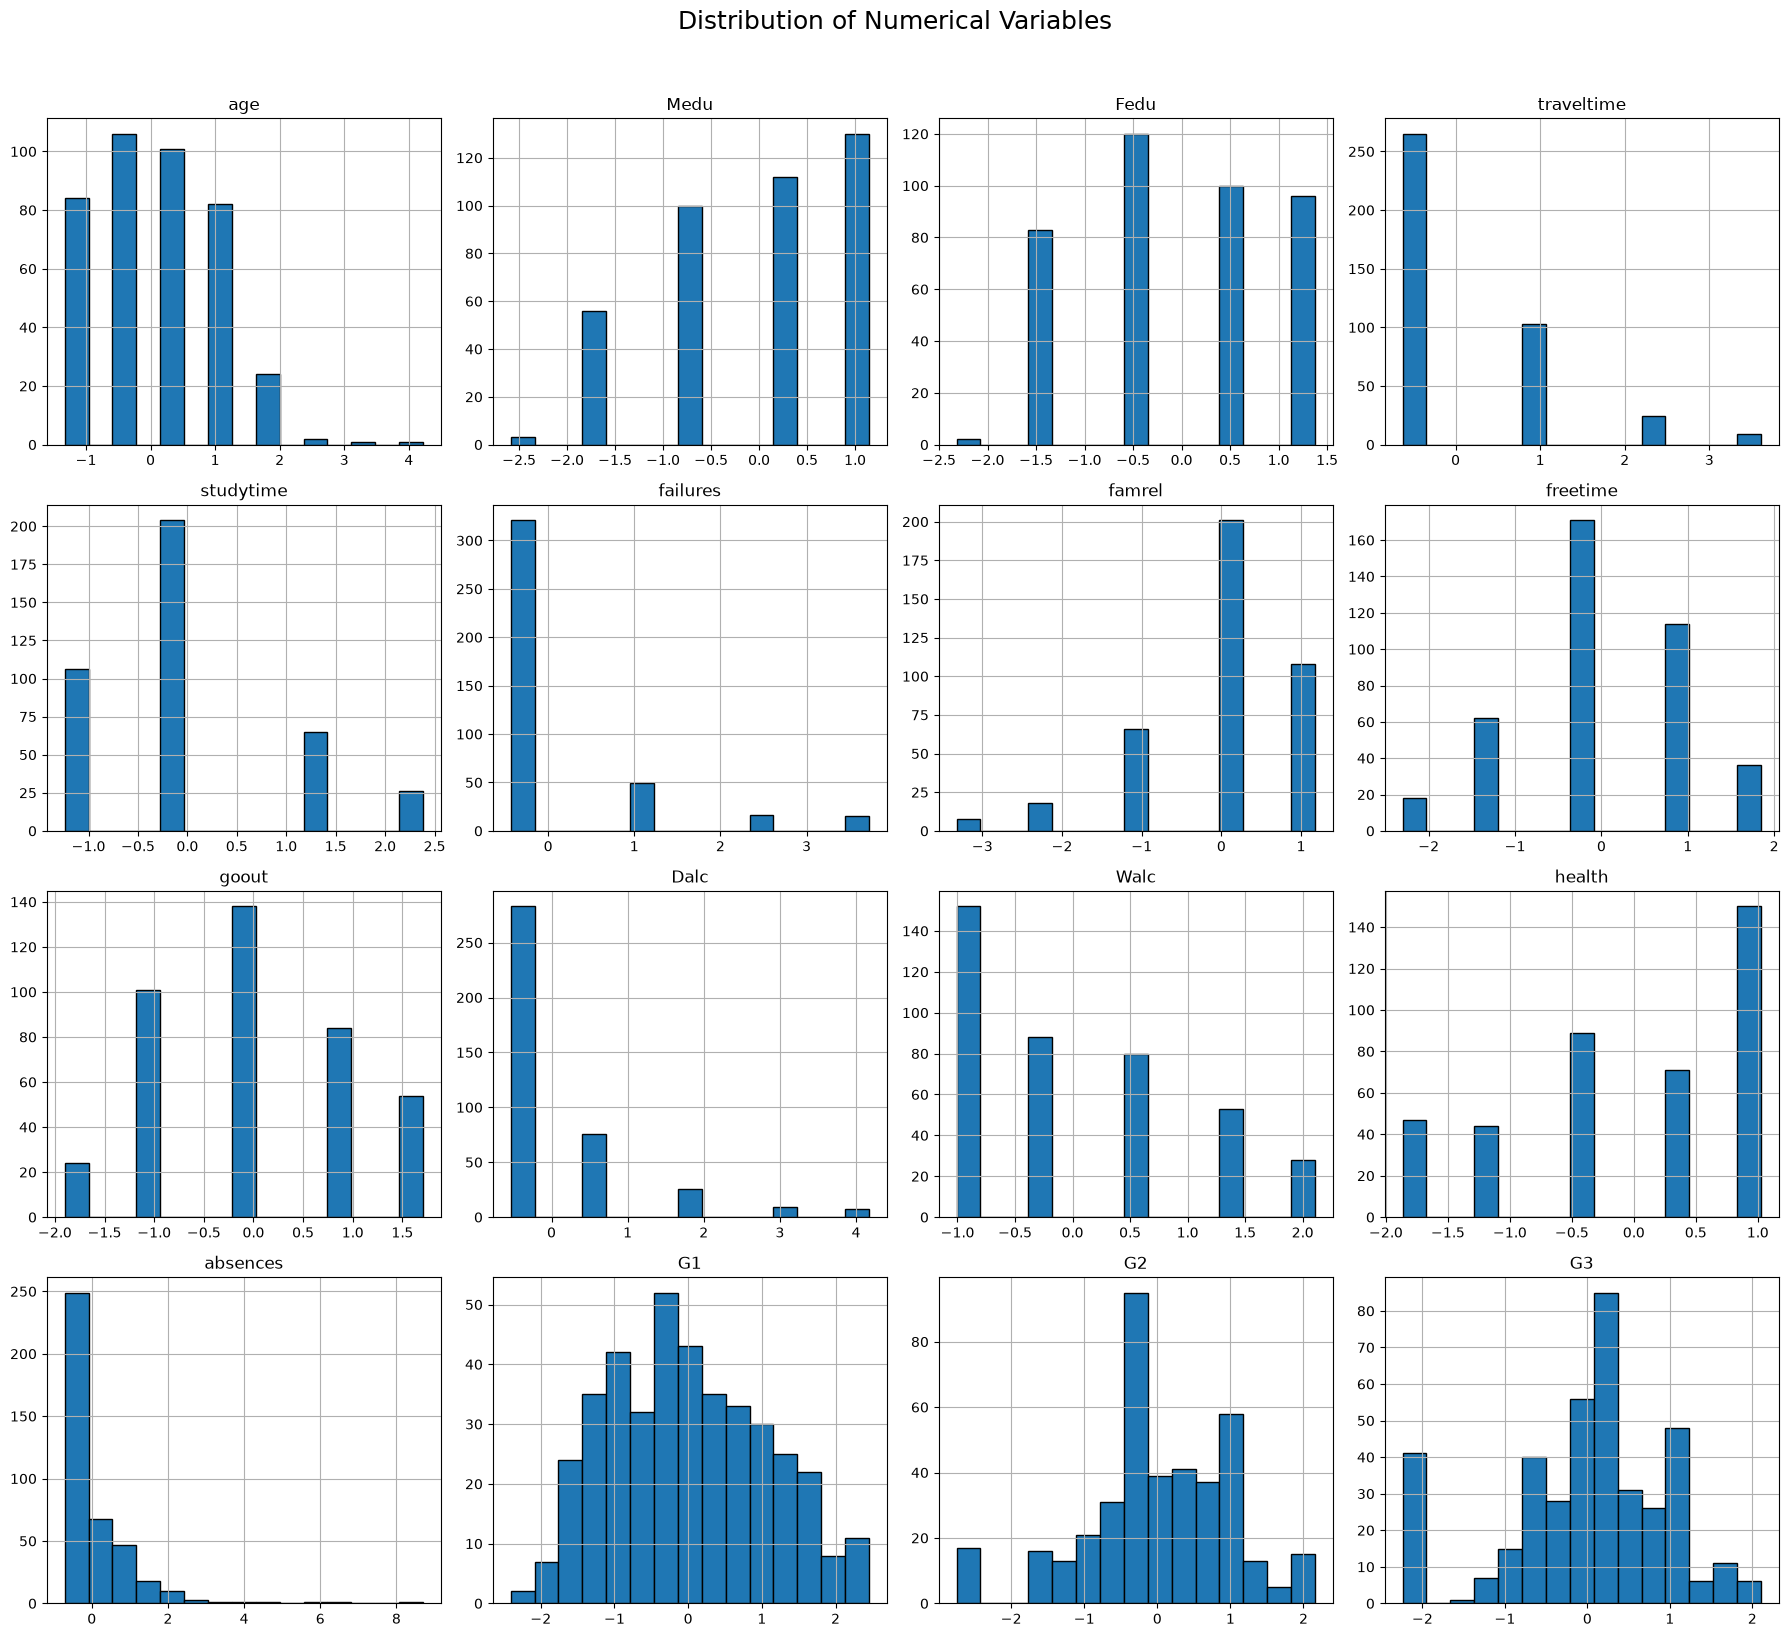

In [14]:
df[numerical_cols].hist(
    bins=15,
    figsize=(18, 16),
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Variables",
    fontsize=18,
    y=1.02
)

plt.tight_layout()

## 2.3 Boxplots – Detecting potential outliers

Axes(0.759073,0.0365645;0.232102x0.191507)


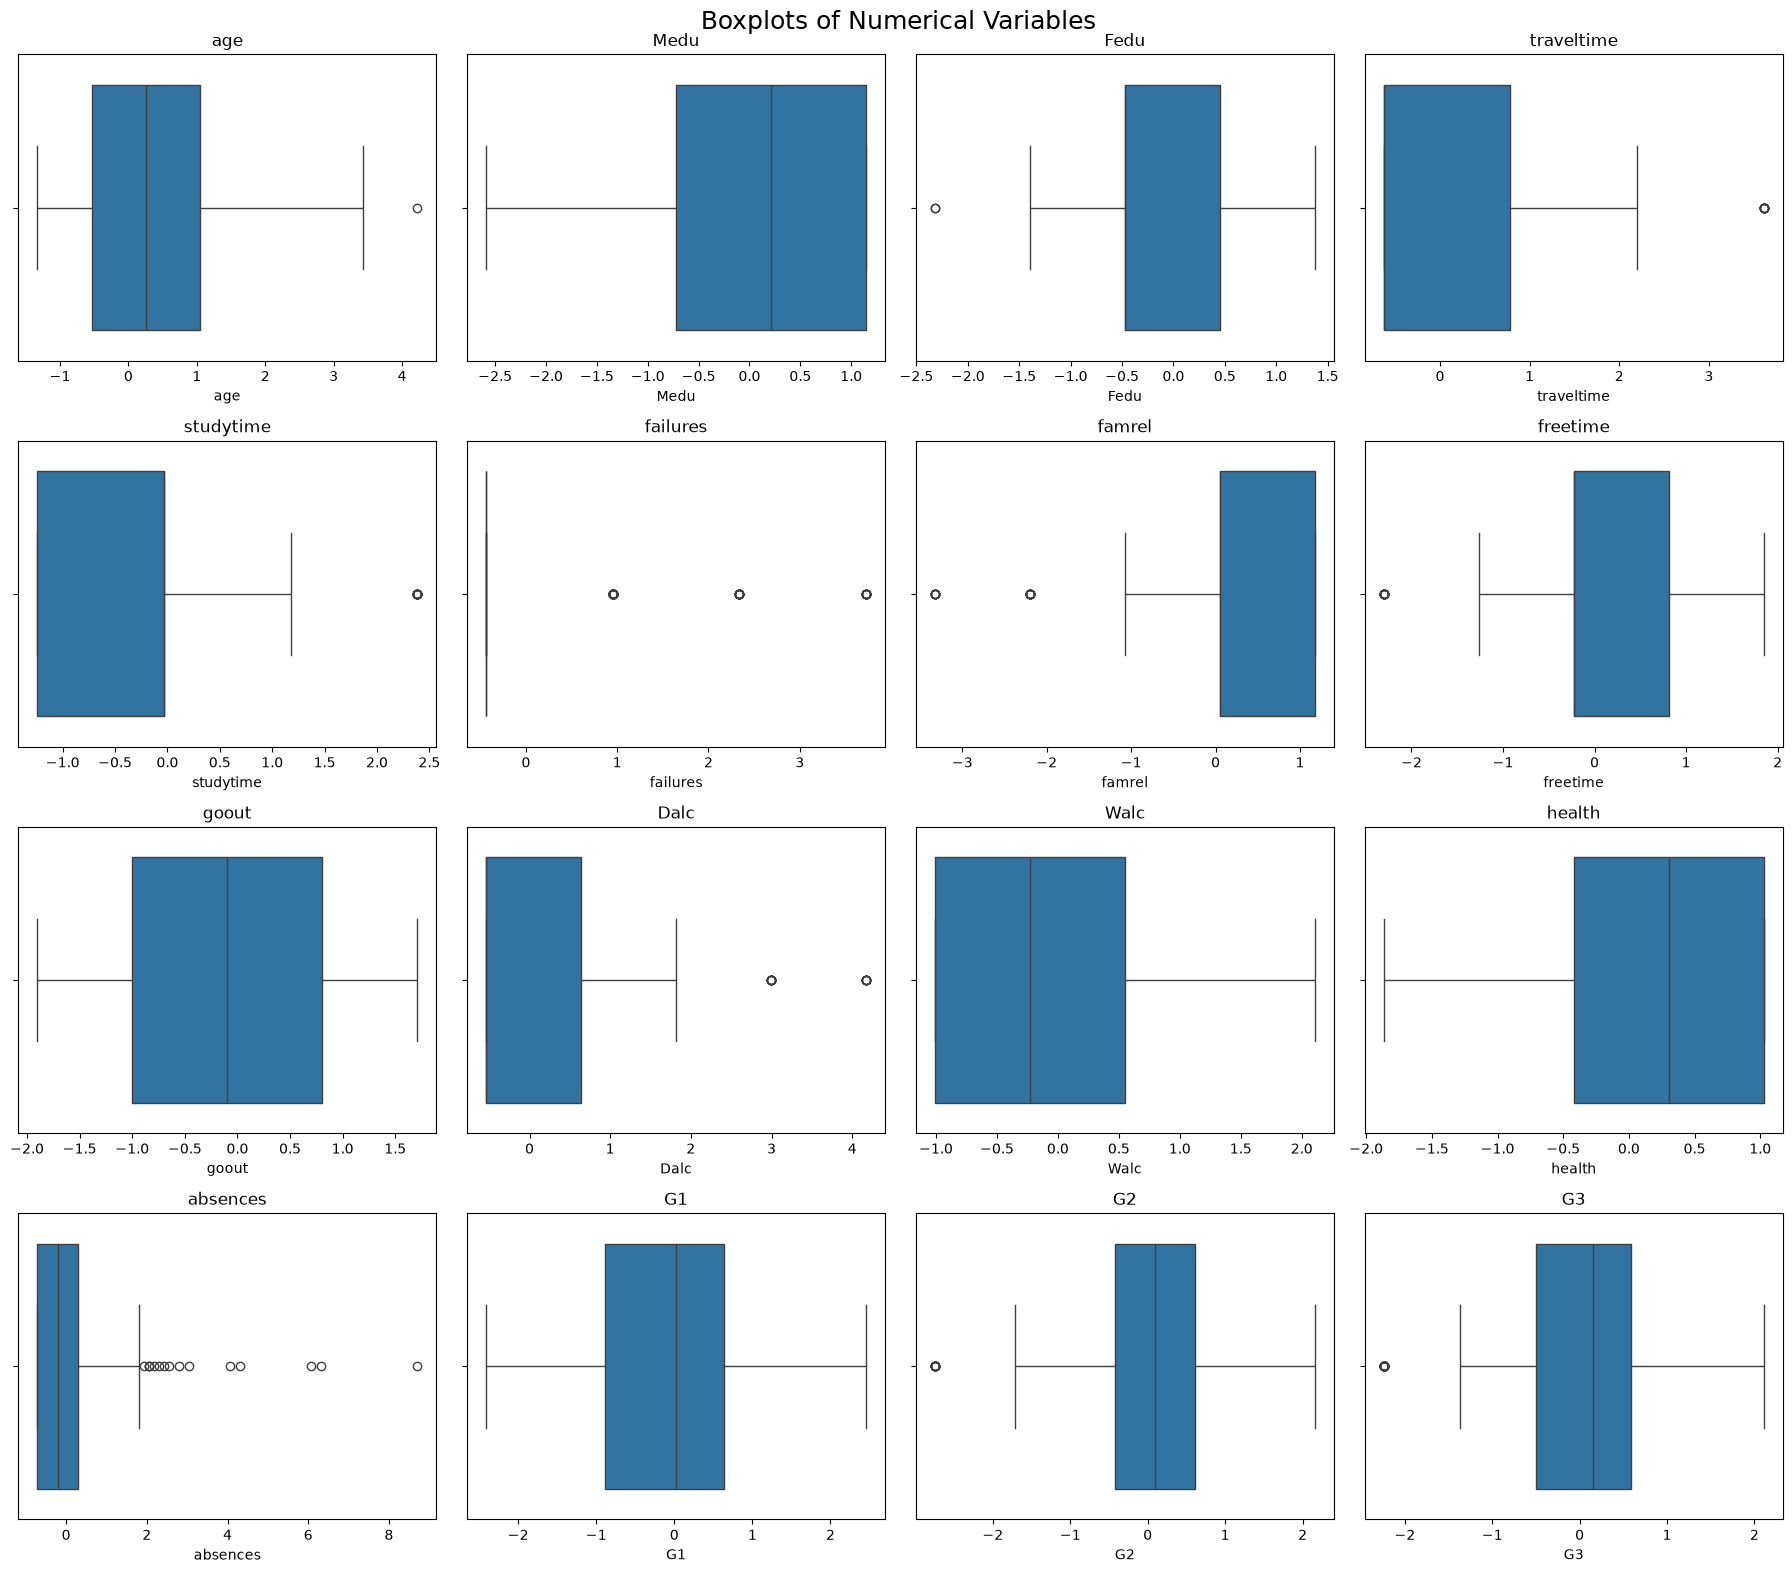

In [ ]:
fig, axes = plt.subplots(
    nrows=4,
    ncols=4,
    figsize=(18, 16)
)


for ax, col in zip(axes.flatten(), numerical_cols):

    sns.boxplot(
        data=df,
        x=col,
        ax=ax
    )

    ax.set_title(col)

plt.suptitle(
    "Boxplots of Numerical Variables",
    fontsize=18
)

plt.tight_layout()

# 3. Univariate analysis – Categorical variables

### 3.1 Categorical variables

We analyze categorical variables to understand the composition
of the student population.

Count plots display the number of observations in each category.

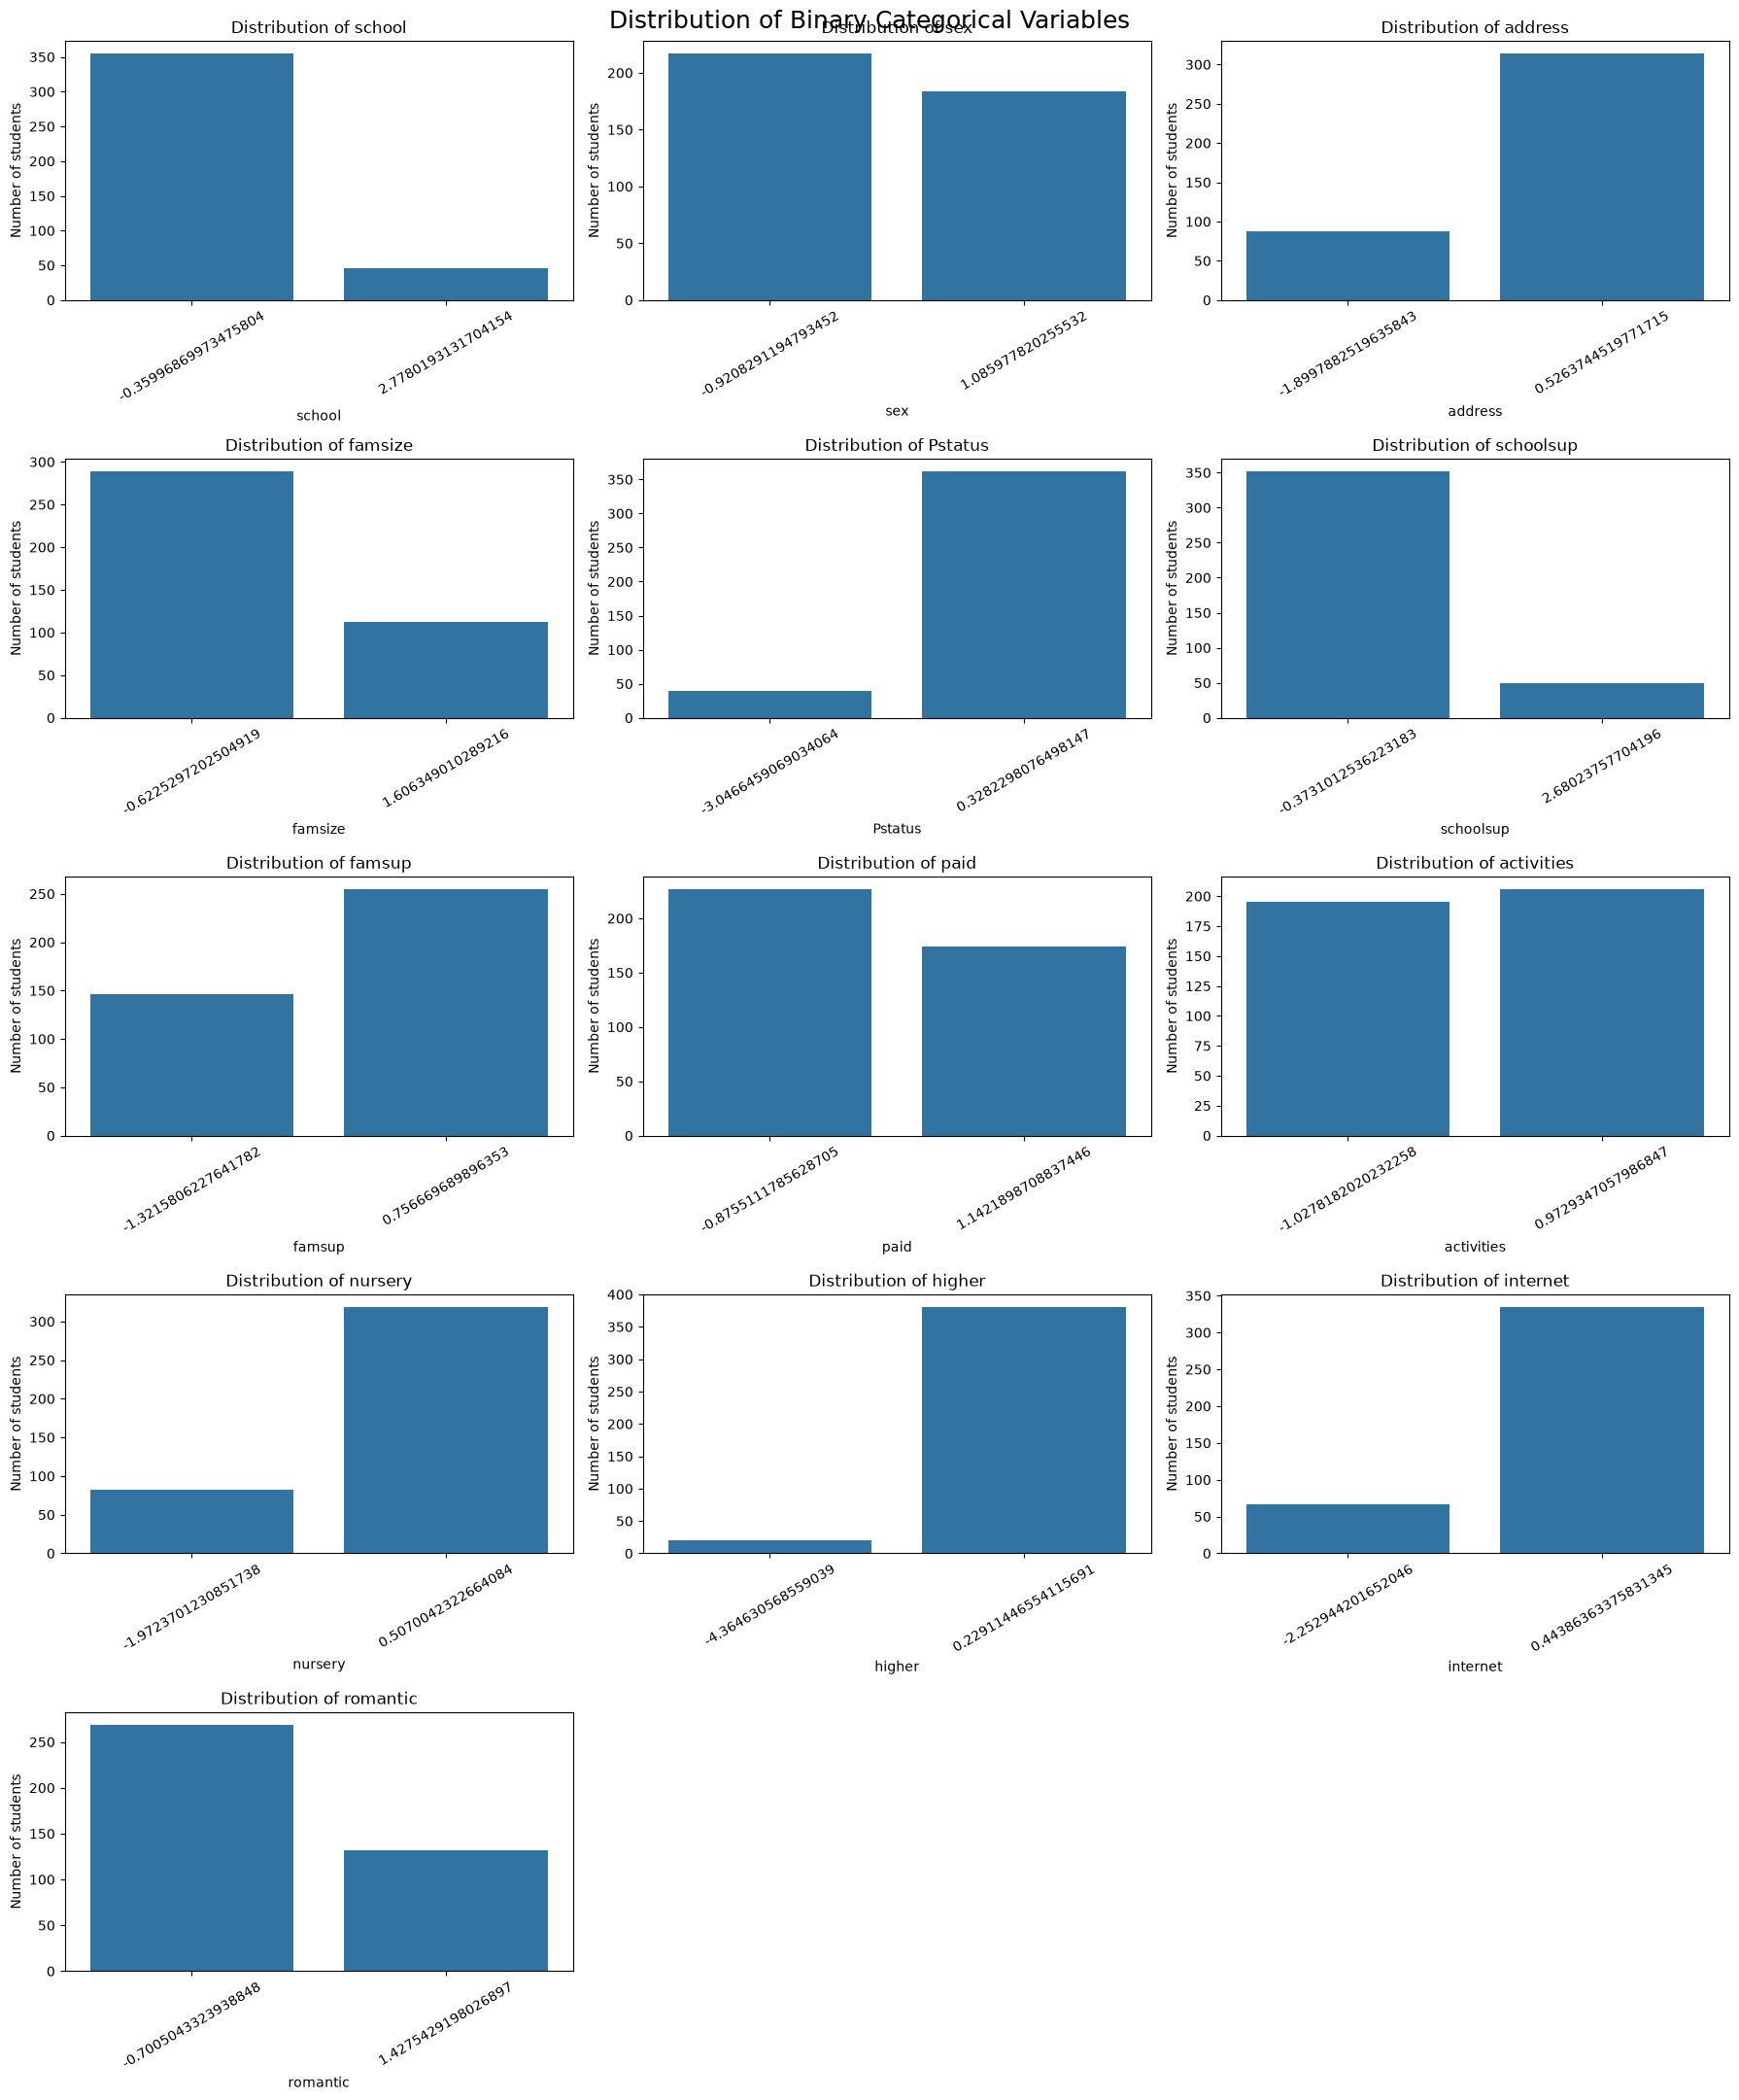

In [ ]:
fig, axes = plt.subplots(
    nrows=5,
    ncols=3,
    figsize=(18, 22)
)

for ax, col in zip(axes.flatten(), binary_cols):

    sns.countplot(
        data=df,
        x=col,
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of students")

    ax.tick_params(axis="x", rotation=30)

for ax in axes.flatten()[len(binary_cols):]:
    ax.remove()

plt.suptitle(
    "Distribution of Binary Categorical Variables",
    fontsize=18
)

plt.tight_layout()

### 3.2 Distribution of One-Hot Encoded Variables

One-Hot Encoding transforms categorical variables into binary columns.

A value of:
- 1 indicates that the observation belongs to the category.
- 0 indicates that the observation does not belong to the category.

We visualize the frequency of each encoded category.

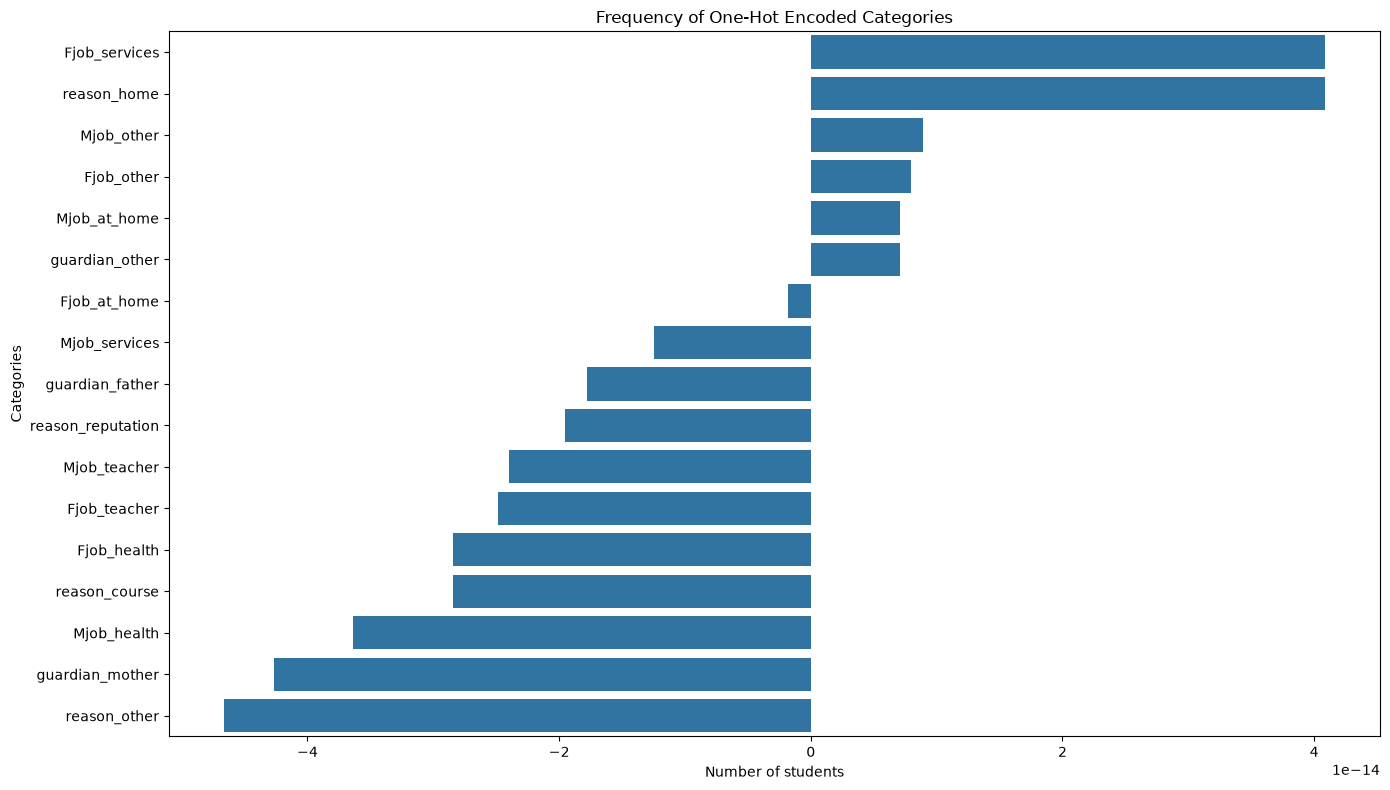

In [19]:
encoded_counts = df[encoded_cols].sum().sort_values(
    ascending=False
)

plt.figure(figsize=(14, 8))

sns.barplot(
    x=encoded_counts.values,
    y=encoded_counts.index
)

plt.title("Frequency of One-Hot Encoded Categories")
plt.xlabel("Number of students")
plt.ylabel("Categories")

plt.tight_layout()

## 4. Bivariate Analysis

Bivariate analysis investigates the relationship between
two variables.

We begin by studying the relationship between numerical
features and the target variable G3.

### 4.1 Correlation with the final grade

Pearson correlation measures the strength and direction
of a linear relationship between two numerical variables.

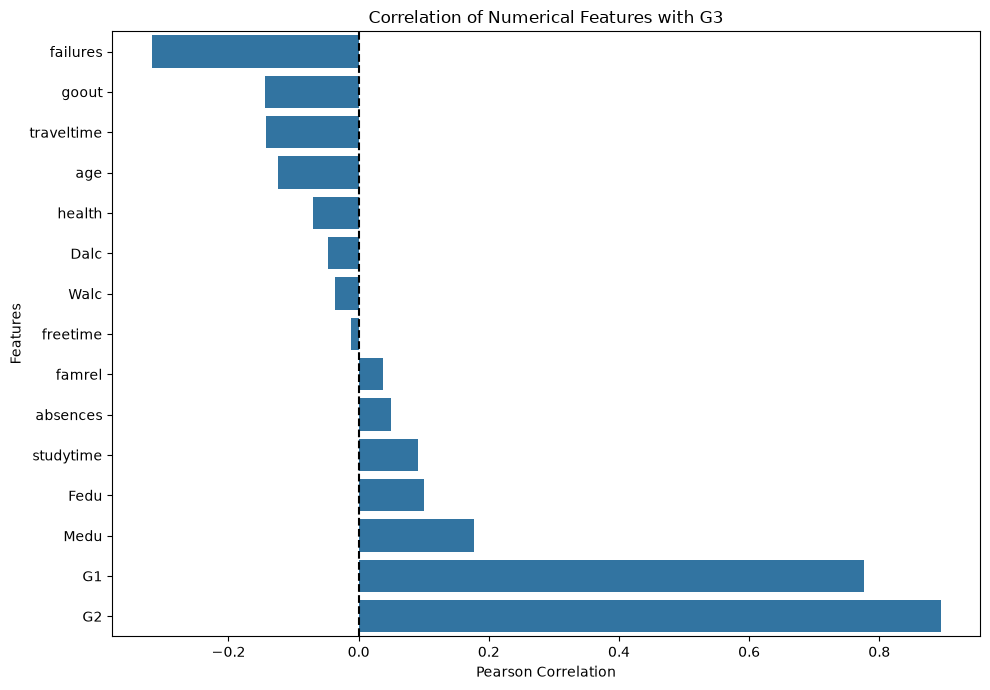

In [21]:
correlation_with_target = (
    df[numerical_cols]
    .corr()["G3"]
    .drop("G3")
    .sort_values()
)

plt.figure(figsize=(10, 7))

sns.barplot(
    x=correlation_with_target.values,
    y=correlation_with_target.index
)

plt.axvline(0, color="black", linestyle="--")

plt.title("Correlation of Numerical Features with G3")
plt.xlabel("Pearson Correlation")
plt.ylabel("Features")

plt.tight_layout()

### 4.2 Scatterplots

Scatterplots allow us to visualize relationships between
numerical variables.

We investigate whether changes in numerical features
are associated with changes in final grades.

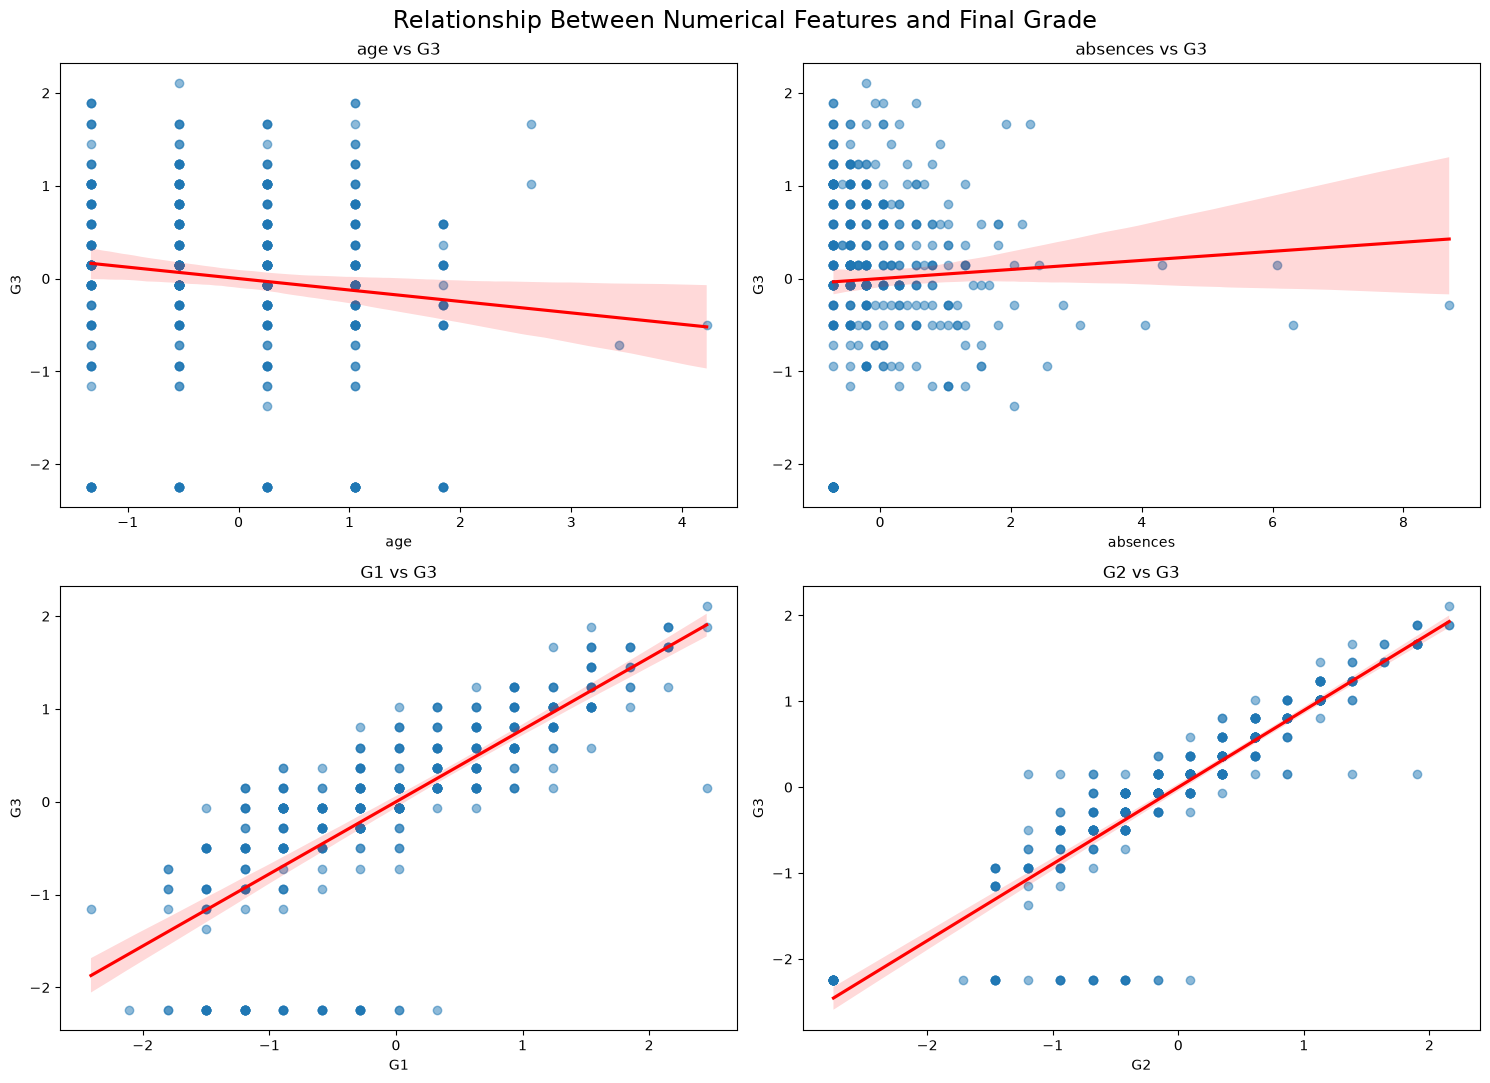

In [22]:
features_to_plot = [
    "age",
    "absences",
    "G1",
    "G2"
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(15, 11)
)

for ax, col in zip(axes.flatten(), features_to_plot):

    sns.regplot(
        data=df,
        x=col,
        y="G3",
        ax=ax,
        scatter_kws={"alpha": 0.5},
        line_kws={"color": "red"}
    )

    ax.set_title(f"{col} vs G3")

plt.suptitle(
    "Relationship Between Numerical Features and Final Grade",
    fontsize=17
)

plt.tight_layout()

## 4.3 Boxplots – Ordinal features vs G3

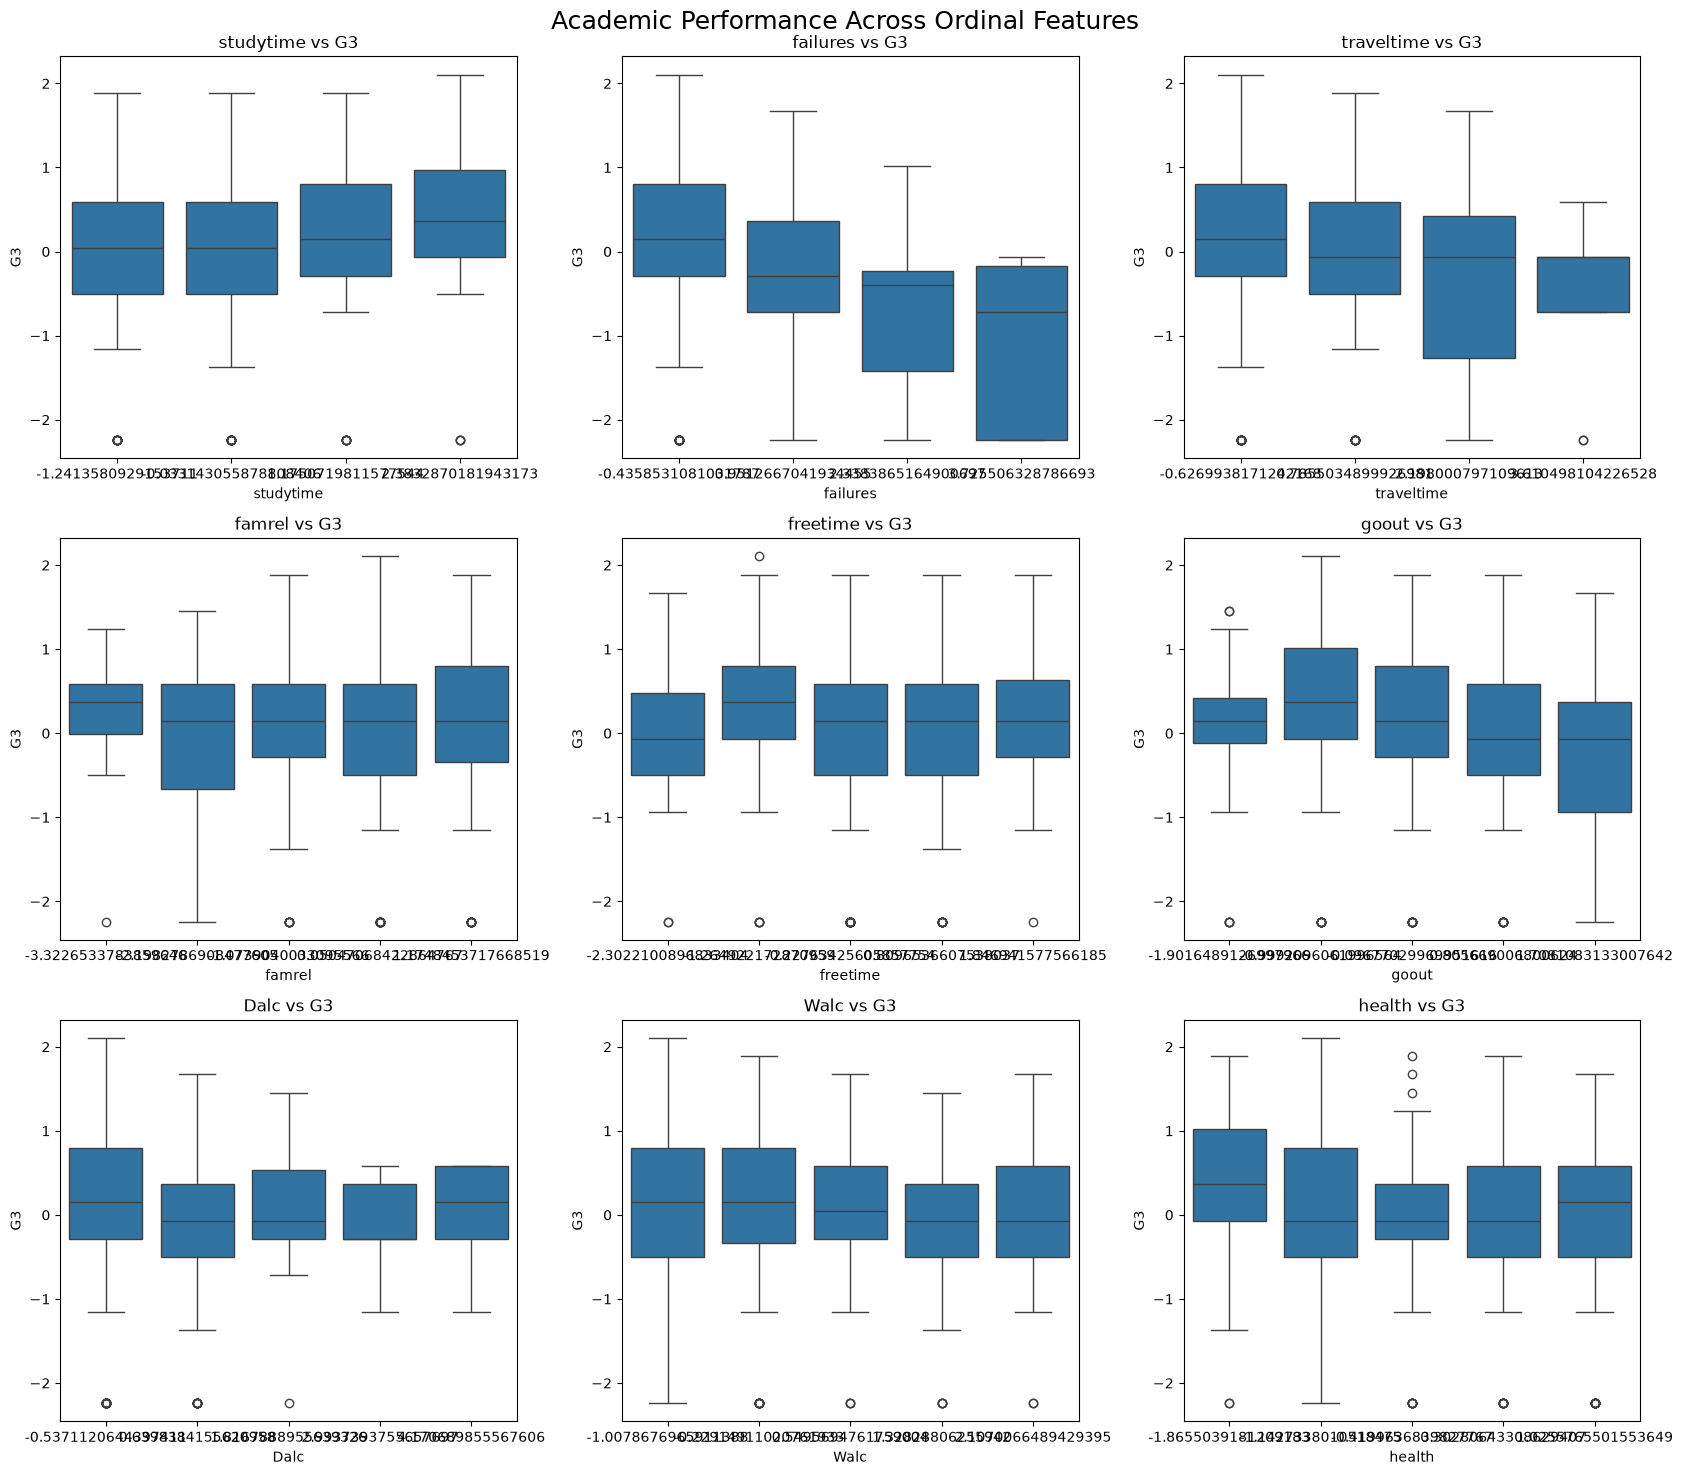

In [23]:
ordinal_features = [
    "studytime",
    "failures",
    "traveltime",
    "famrel",
    "freetime",
    "goout",
    "Dalc",
    "Walc",
    "health"
]

fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(17, 15)
)

for ax, col in zip(axes.flatten(), ordinal_features):

    sns.boxplot(
        data=df,
        x=col,
        y="G3",
        ax=ax
    )

    ax.set_title(f"{col} vs G3")

plt.suptitle(
    "Academic Performance Across Ordinal Features",
    fontsize=18
)

plt.tight_layout()

## 5. Bivariate Analysis: Categorical Features vs G3

We investigate whether students belonging to different
categorical groups have different distributions of final grades.

Boxplots allow us to compare the median, dispersion
and potential outliers of each group.

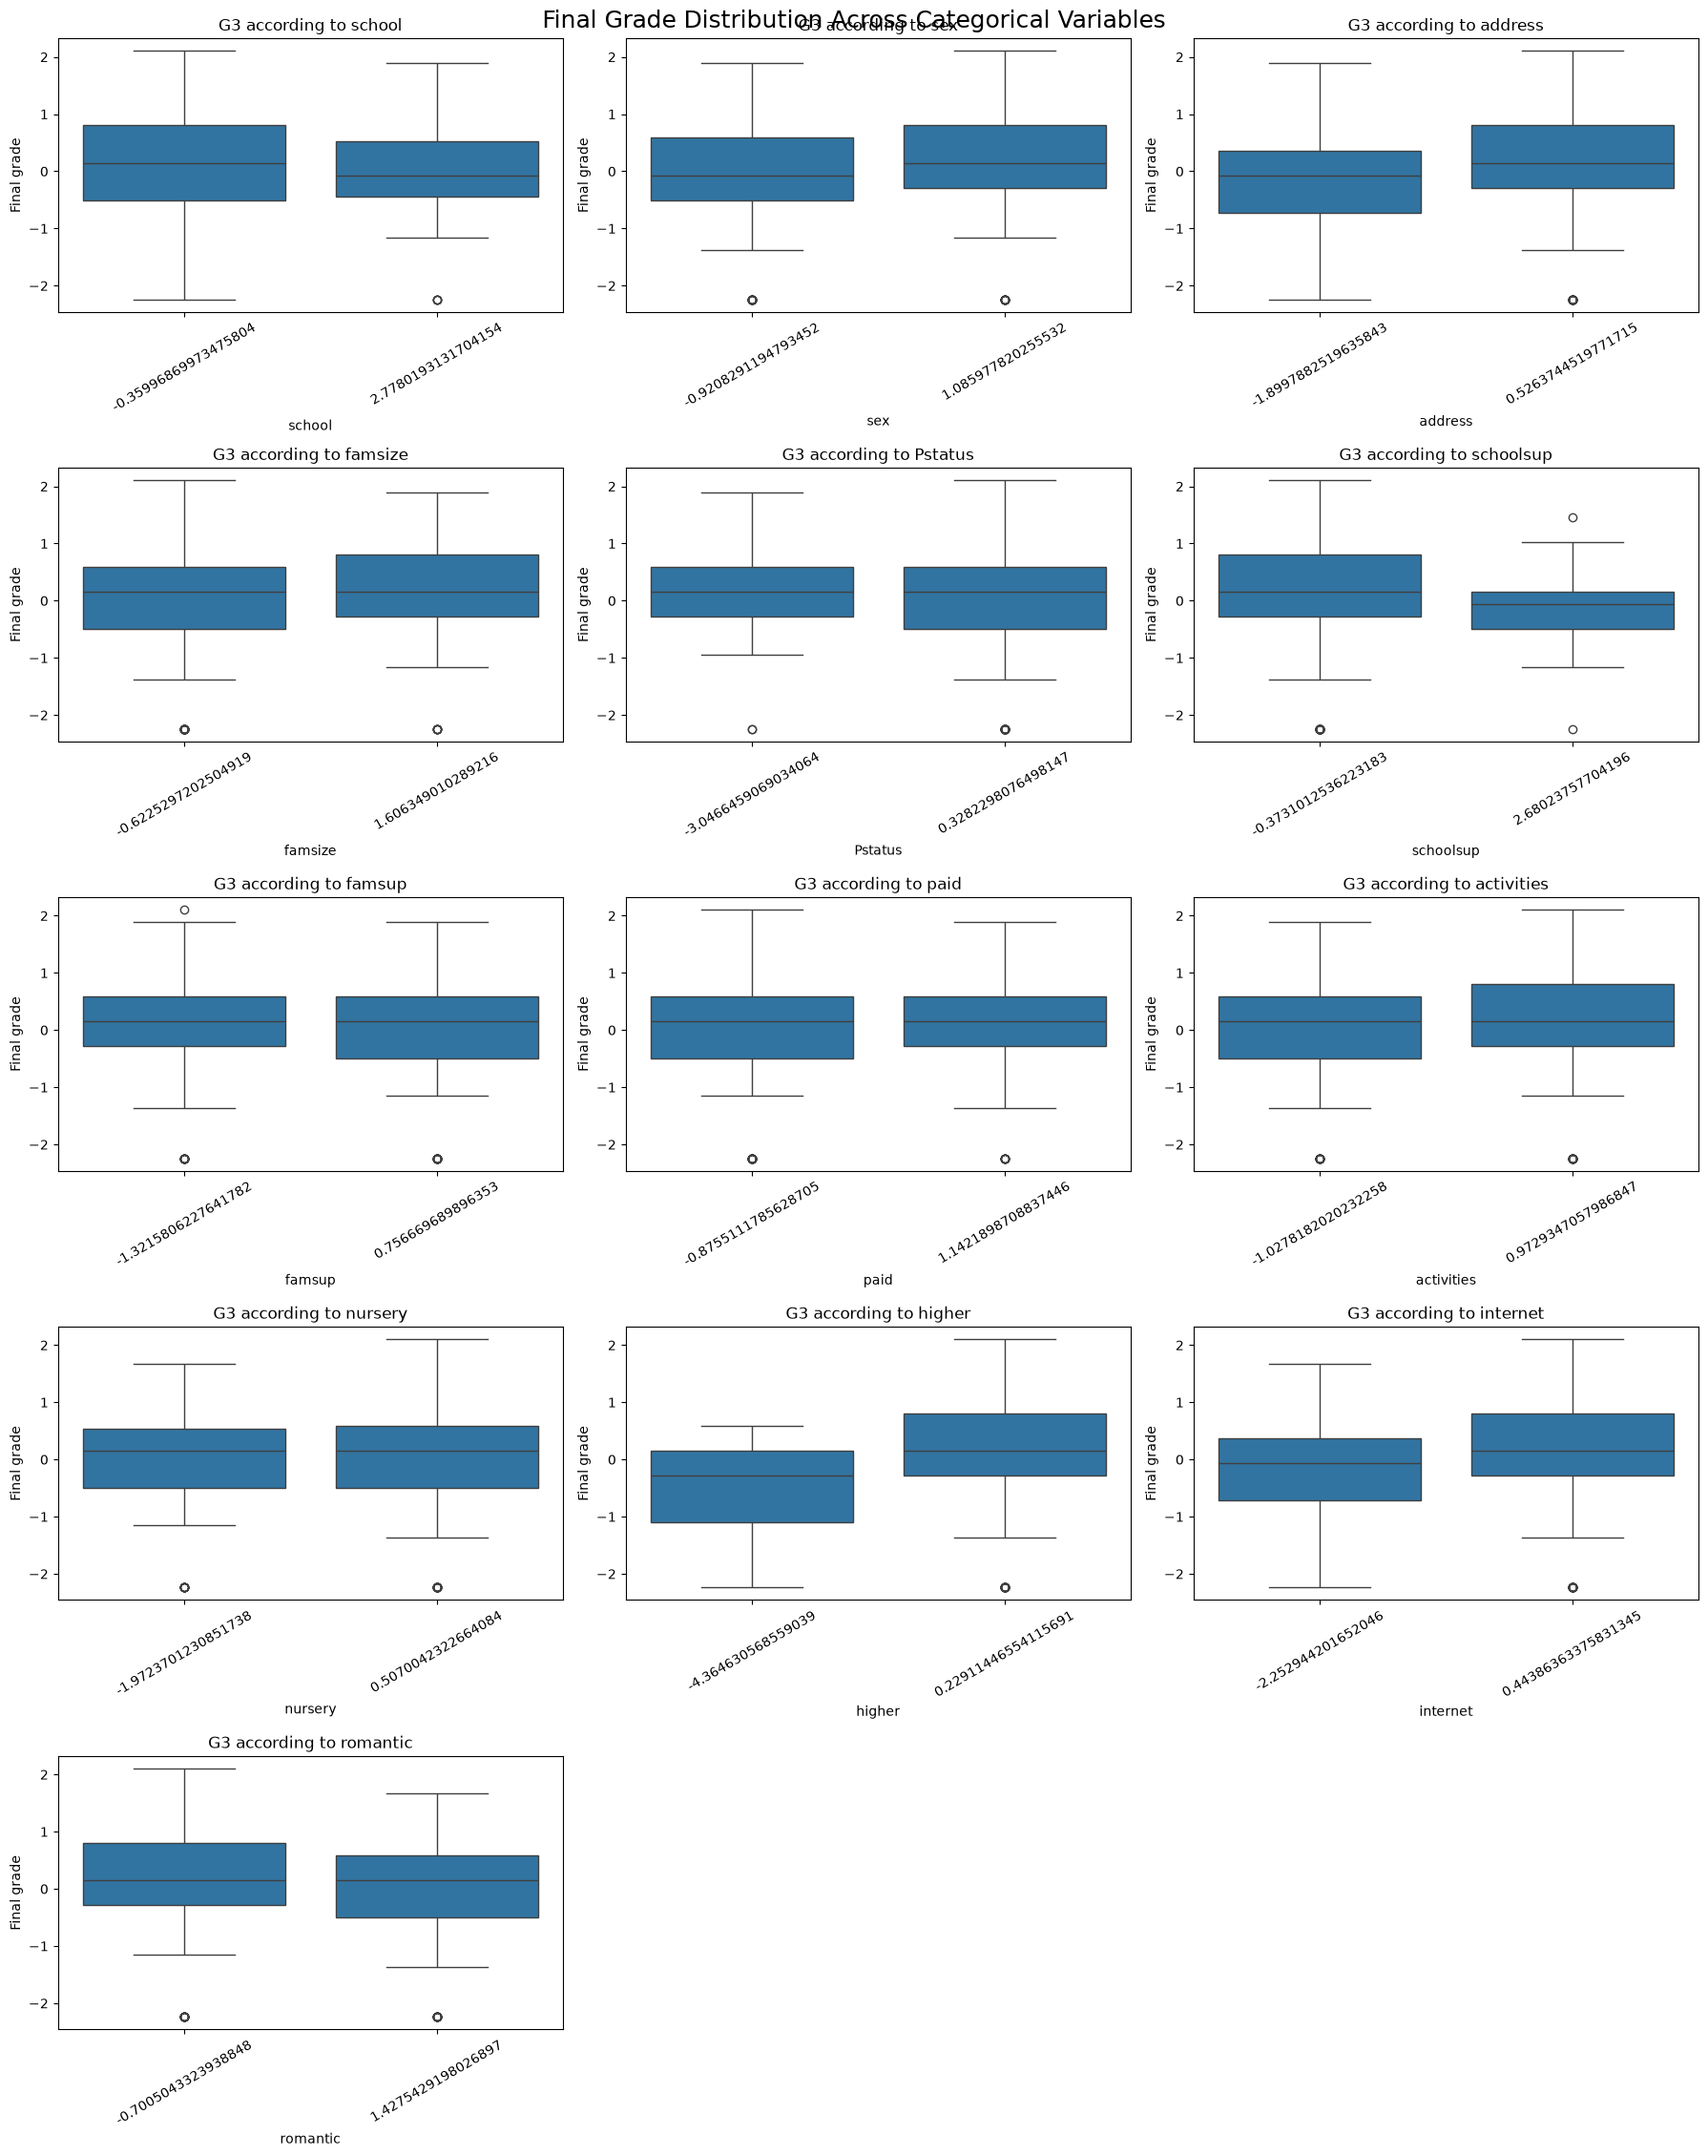

In [24]:
fig, axes = plt.subplots(
    nrows=5,
    ncols=3,
    figsize=(18, 23)
)

for ax, col in zip(axes.flatten(), binary_cols):

    sns.boxplot(
        data=df,
        x=col,
        y="G3",
        ax=ax
    )

    ax.set_title(f"G3 according to {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Final grade")

    ax.tick_params(axis="x", rotation=30)

for ax in axes.flatten()[len(binary_cols):]:
    ax.remove()

plt.suptitle(
    "Final Grade Distribution Across Categorical Variables",
    fontsize=18
)

plt.tight_layout()

## 6. Multivariate Analysis

Multivariate analysis investigates relationships between
multiple variables simultaneously.

### 6.1 Correlation Matrix

A correlation matrix provides an overview of linear
relationships between numerical variables.

A heatmap represents correlation coefficients using colors.

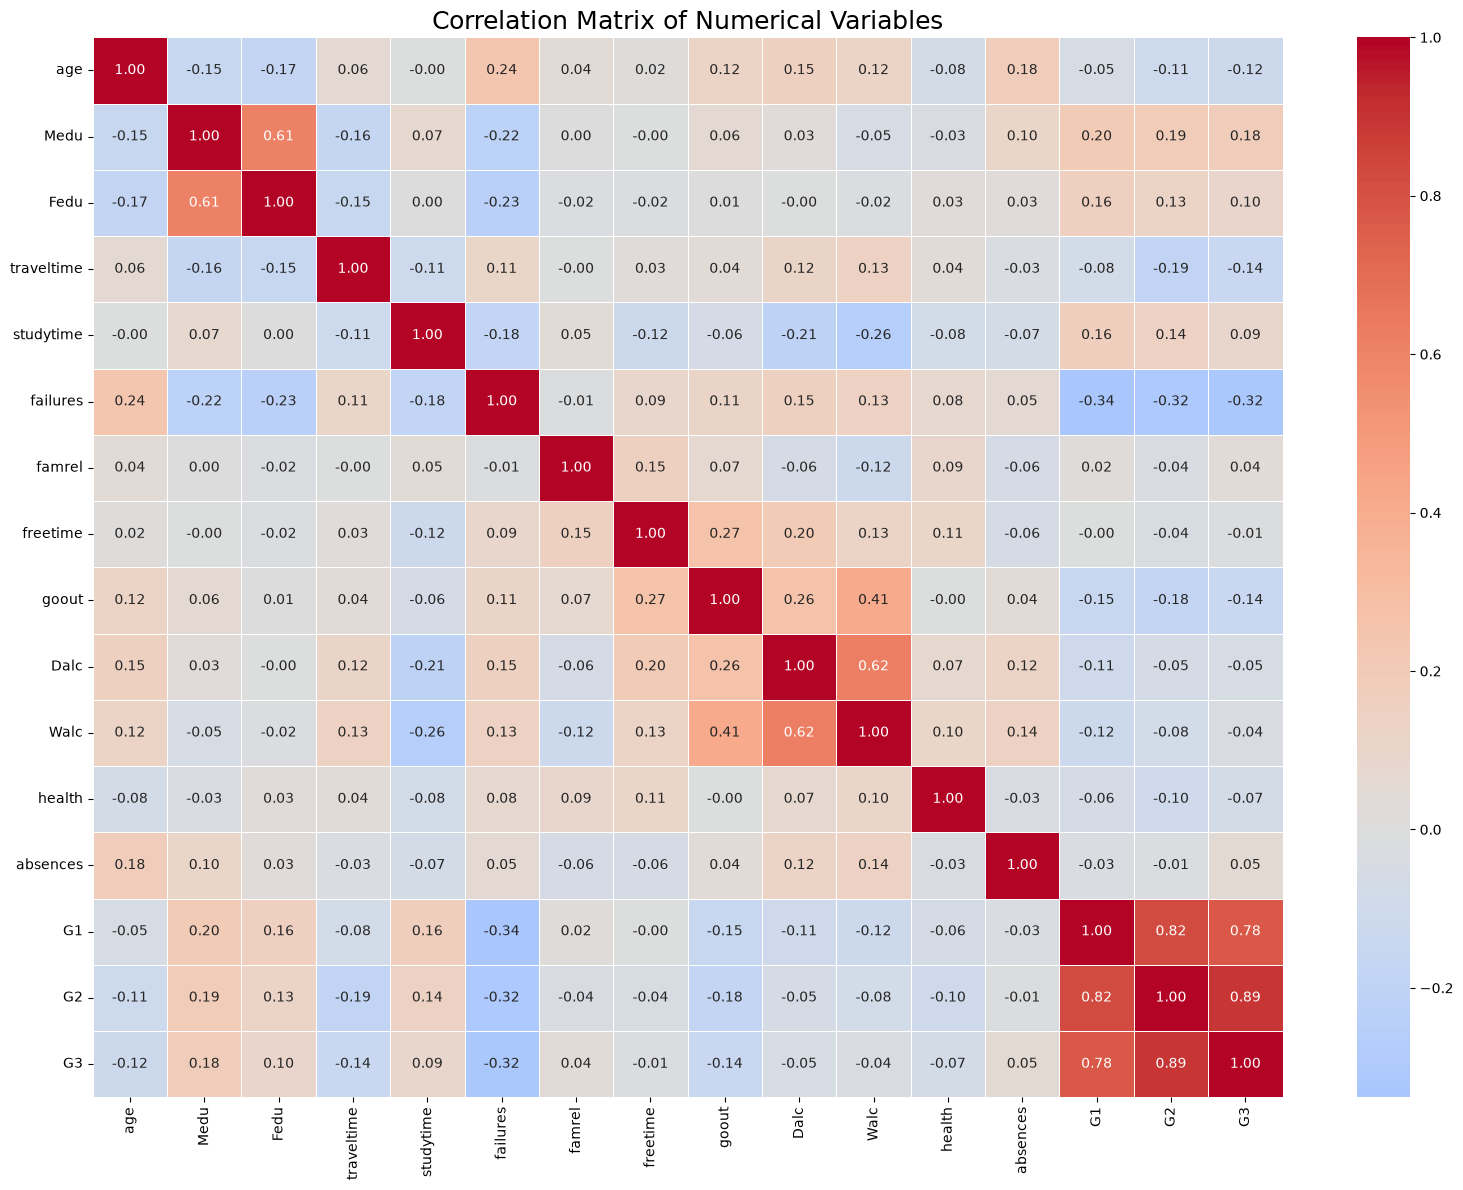

In [25]:
correlation_matrix = df[numerical_cols].corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title(
    "Correlation Matrix of Numerical Variables",
    fontsize=18
)

plt.tight_layout()

### 6.2 Pairplot

A pairplot displays pairwise relationships between several
numerical variables.

It combines:
- Scatterplots for relationships between different variables.
- Histograms or density plots for individual variables.

We select a small number of important features to avoid
creating an excessively large visualization.

Text(0.5, 1.02, 'Pairwise Relationships Between Academic Variables')

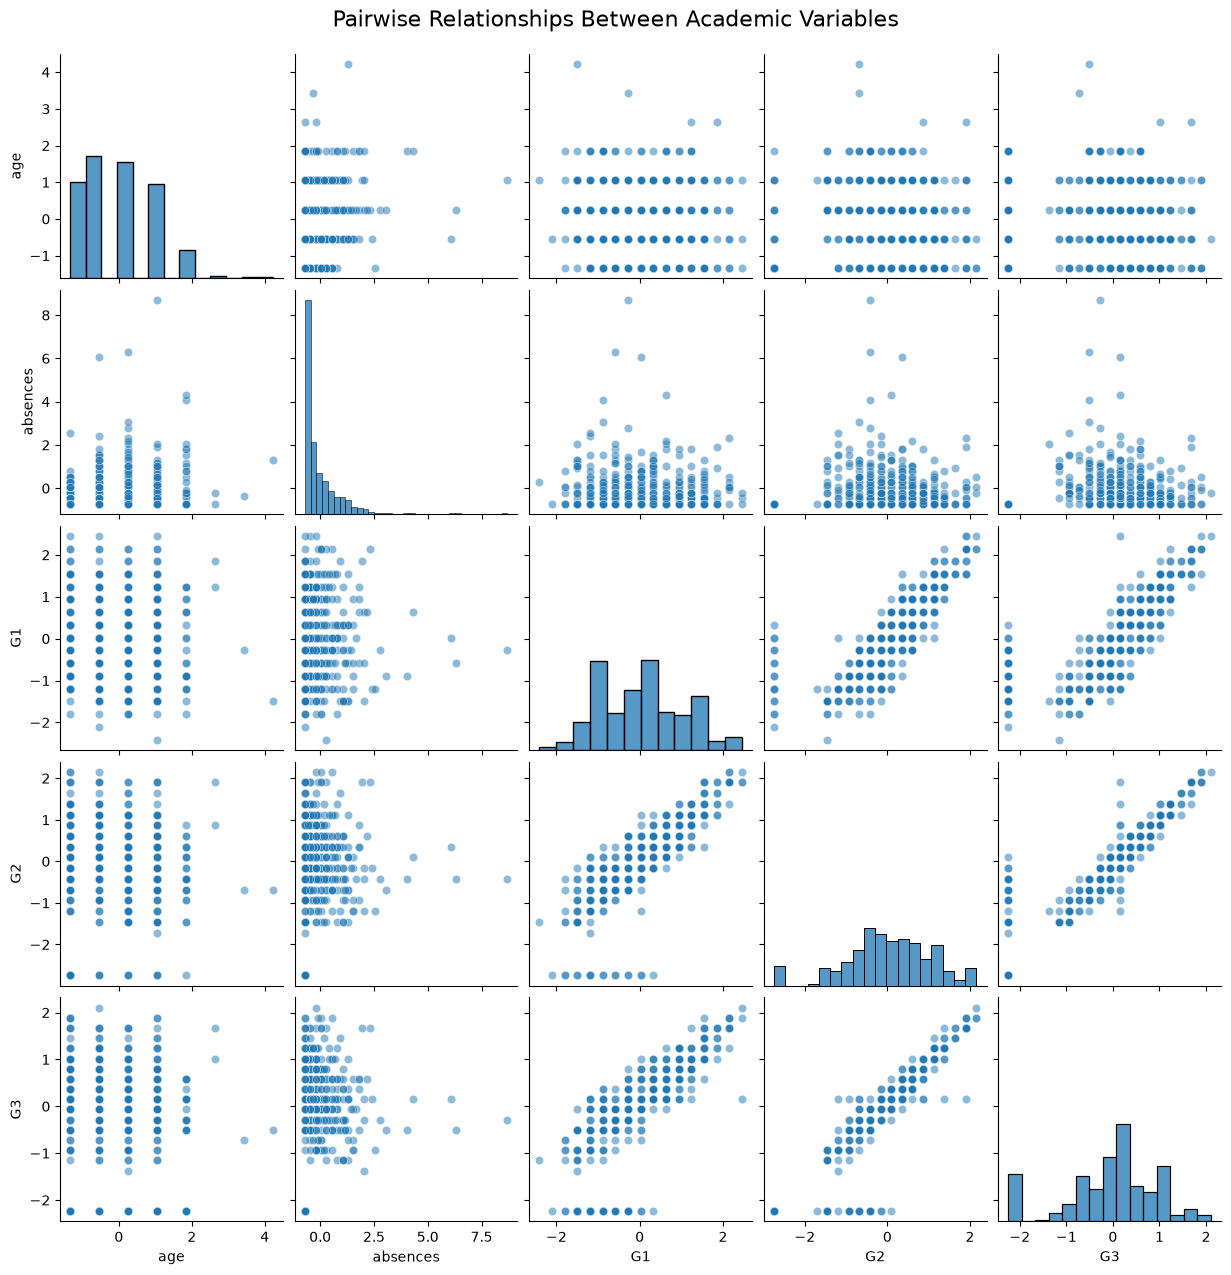

In [26]:
pairplot_features = [
    "age",
    "absences",
    "G1",
    "G2",
    "G3"
]

sns.pairplot(
    df[pairplot_features],
    diag_kind="hist",
    plot_kws={"alpha": 0.5}
)

plt.suptitle(
    "Pairwise Relationships Between Academic Variables",
    y=1.02,
    fontsize=16
)

### 6.3 Academic Grade Progression

We examine the evolution of students' academic performance
across the three grading periods.

The objective is to understand whether students generally
improve, maintain or decrease their performance.

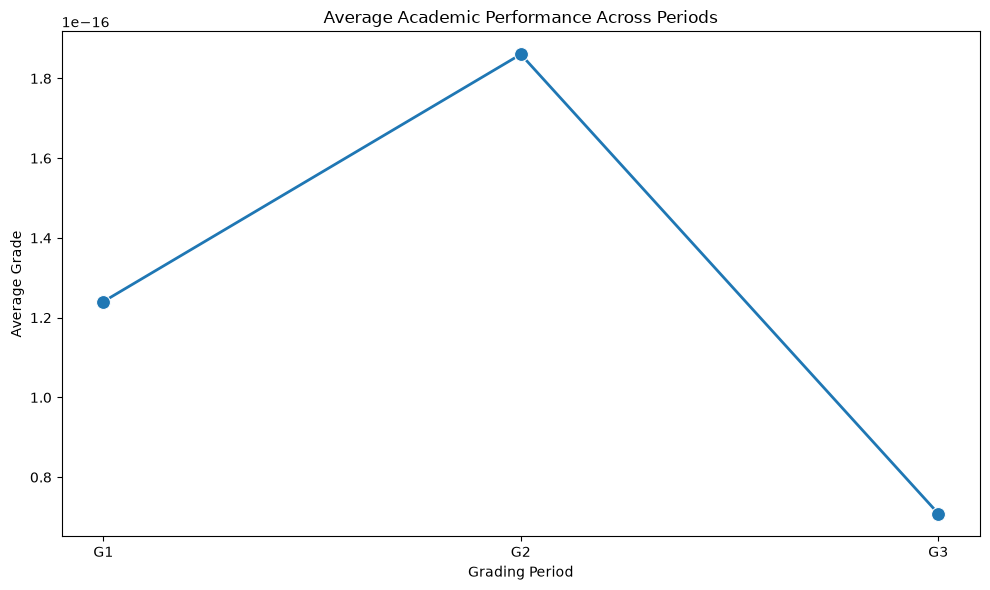

In [27]:
grades = ["G1", "G2", "G3"]

mean_grades = df[grades].mean()

plt.figure(figsize=(10, 6))

sns.lineplot(
    x=grades,
    y=mean_grades.values,
    marker="o",
    linewidth=2,
    markersize=10
)

plt.title("Average Academic Performance Across Periods")
plt.xlabel("Grading Period")
plt.ylabel("Average Grade")

plt.xticks(grades)
plt.tight_layout()

### 6.4 Relationship Between Previous Grades and Final Grade

Previous academic grades may be useful indicators
of future academic performance.

We investigate the relationships between G1, G2 and G3.

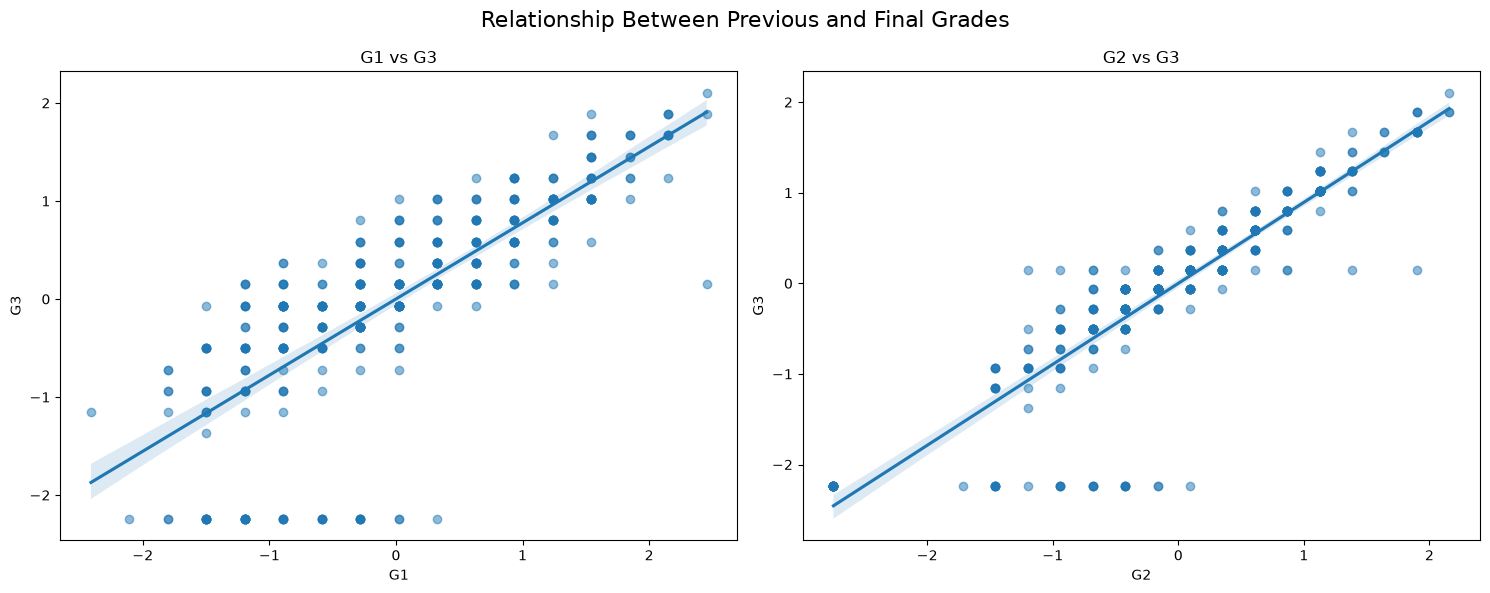

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.regplot(
    data=df,
    x="G1",
    y="G3",
    ax=axes[0],
    scatter_kws={"alpha": 0.5}
)

axes[0].set_title("G1 vs G3")

sns.regplot(
    data=df,
    x="G2",
    y="G3",
    ax=axes[1],
    scatter_kws={"alpha": 0.5}
)

axes[1].set_title("G2 vs G3")

plt.suptitle(
    "Relationship Between Previous and Final Grades",
    fontsize=16
)

plt.tight_layout()

## 7. Academic Performance Analysis

This section focuses on understanding academic performance
through selected student characteristics.

### 7.1 Final Grade Distribution by Gender

We compare the distribution of final grades between
male and female students.

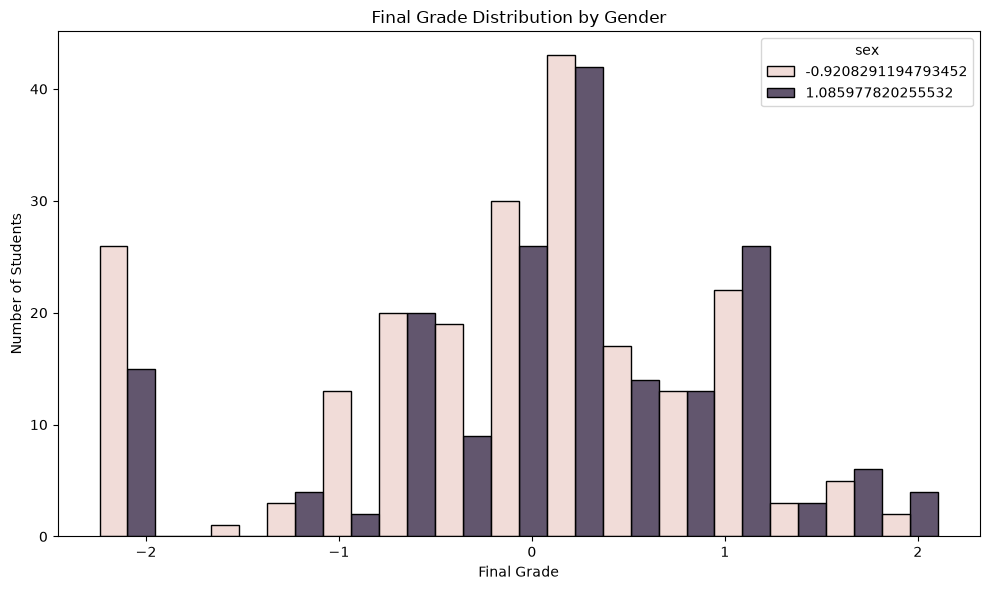

In [29]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="G3",
    hue="sex",
    multiple="dodge",
    bins=15,
    kde=False
)

plt.title("Final Grade Distribution by Gender")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")

plt.tight_layout()

### 7.2 Study Time and Academic Performance

We investigate the relationship between weekly study time
and students' final grades.

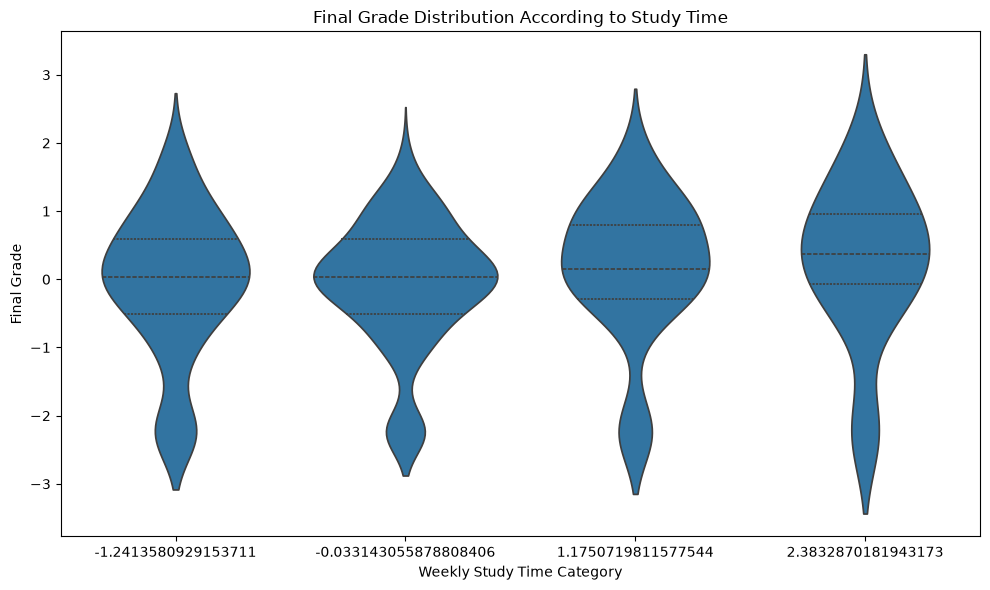

In [30]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x="studytime",
    y="G3",
    inner="quartile"
)

plt.title("Final Grade Distribution According to Study Time")
plt.xlabel("Weekly Study Time Category")
plt.ylabel("Final Grade")

plt.tight_layout()

### 7.3 Absences and Academic Performance

We investigate whether the number of school absences
is associated with students' final grades.

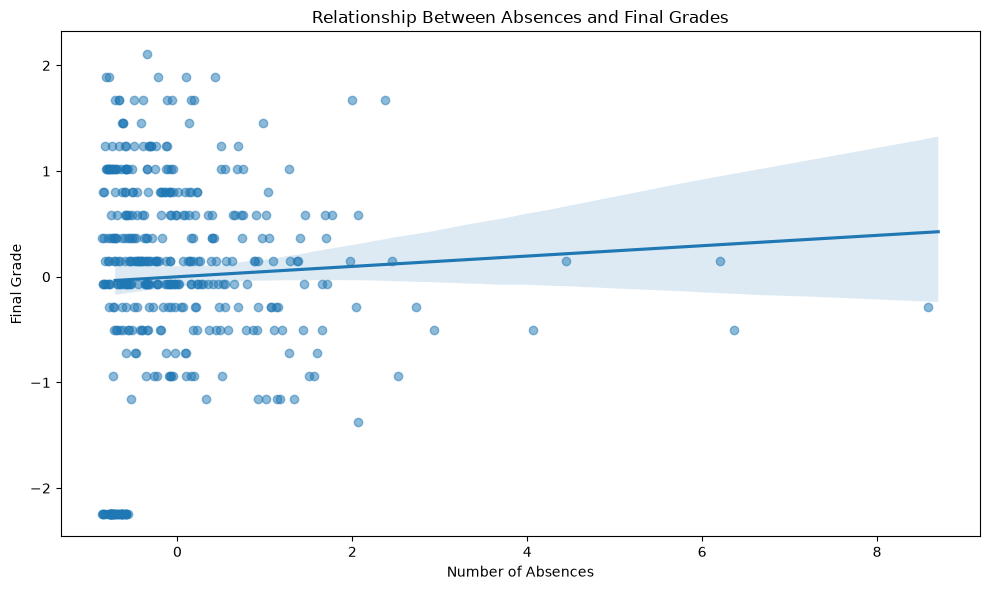

In [31]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="absences",
    y="G3",
    x_jitter=0.15,
    scatter_kws={"alpha": 0.5}
)

plt.title("Relationship Between Absences and Final Grades")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade")

plt.tight_layout()
plt.show()

### 7.4 Previous Failures and Academic Performance

We compare students' final grades according to their
number of previous class failures.

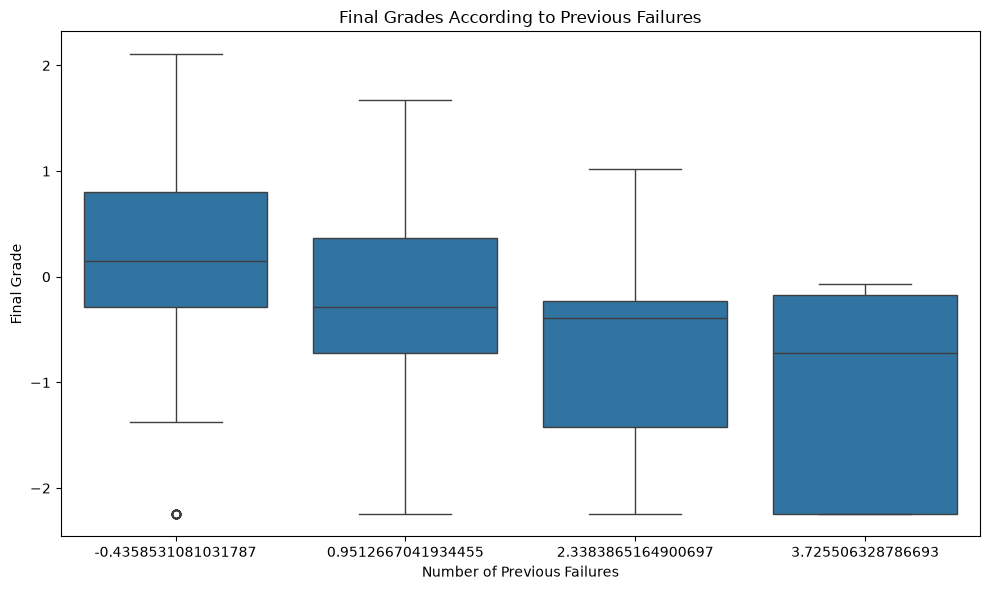

In [32]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="failures",
    y="G3"
)

plt.title("Final Grades According to Previous Failures")
plt.xlabel("Number of Previous Failures")
plt.ylabel("Final Grade")

plt.tight_layout()